# 📊 Dataset Design & Data Preparation for SLM Fine-Tuning

> **Part of the [SLM Fine-Tuning Tutorial](https://github.com/Kumarjit-Pathak/finetuning-slm)**

## What You'll Learn

This notebook goes beyond "just load a dataset from HuggingFace." You'll learn to **design and construct** fine-tuning datasets from scratch, understand why data quality matters more than quantity, and avoid common pitfalls that silently destroy model performance.

### Contents
| Part | Topic | Key Takeaway |
|------|-------|-------------|
| **A** | Dataset Design Principles | Your objective determines your data requirements |
| **B** | Labeling Strategies | Synthetic data is powerful but dangerous |
| **C** | Data Governance & Licensing | Ignoring licenses can kill your project |
| **D** | Practical Implementation | Tokenizers, chat templates, quality checks |
| **🔴** | Failure Point #1 | Wrong chat template → garbled output |
| **🔴** | Failure Point #2 | PII leakage → model memorizes secrets |

### Prerequisites
- Completed `00_environment_setup.ipynb`
- Basic understanding of transformer models
- ~4GB disk space for datasets and models

---

In [1]:
# ============================================================
# 📦 Colab Setup — Run this cell first if on Google Colab
# ============================================================
# Uncomment the following lines if running on Google Colab:

# !pip install -q transformers datasets accelerate tokenizers
# !pip install -q matplotlib seaborn pandas numpy tqdm
# !pip install -q peft trl bitsandbytes
# !pip install -q presidio-analyzer presidio-anonymizer spacy
# !python -m spacy download en_core_web_sm

# If on Colab, clone the repo for src/ utilities:
# !git clone https://github.com/Kumarjit-Pathak/finetuning-slm.git
# import sys; sys.path.insert(0, 'finetuning-slm')

print("✅ Setup complete!")

✅ Setup complete!


In [2]:
# ============================================================
# 🔧 Imports & Device Detection
# ============================================================
import sys
import os
import warnings
warnings.filterwarnings("ignore")

# Add src/ to path for local utilities
sys.path.insert(0, os.path.abspath("../src"))

# Core imports
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from typing import List, Dict

# HuggingFace ecosystem
from datasets import load_dataset, Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForCausalLM

# Our project utilities
from training_utils import setup_device, get_device_info
from data_utils import (
    load_and_format_dataset,
    apply_chat_template,
    compute_dataset_statistics,
    check_data_quality,
)

# Device detection
device = setup_device()
device_info = get_device_info()
print(f"🖥️  Device: {device_info['device']}")
print(f"📦 Backend: {device_info['backend']}")

# Configuration
LOW_RESOURCE = True  # Set to True for 6GB GPU / Colab free tier
MODEL_NAME = "HuggingFaceTB/SmolLM2-135M-Instruct"  # Smallest model for demos
print(f"\n⚙️  Low resource mode: {LOW_RESOURCE}")
print(f"🤖 Demo model: {MODEL_NAME}")

🖥️  Device: mps
📦 Backend: Metal Performance Shaders (Apple Silicon)

⚙️  Low resource mode: True
🤖 Demo model: HuggingFaceTB/SmolLM2-135M-Instruct


---
## Part A: Dataset Design Principles

### 🎯 The Golden Rule of Fine-Tuning Data

> **Your fine-tuning objective determines EVERYTHING about your data requirements.**

This sounds obvious, but it's the #1 mistake beginners make — grabbing a generic dataset and hoping it works. Different objectives need fundamentally different data:

| Objective | Data Requirement | Example |
|-----------|-----------------|---------|
| **Instruction Tuning** | Diverse instruction/response pairs with varied complexity | "Explain quantum computing" → detailed explanation |
| **Domain Adaptation** | Domain-specific text at volume (quality > diversity) | 50K medical papers for a clinical NLP model |
| **Style Transfer** | Parallel examples in target style (small but pristine) | Formal → casual rewrites (500–2000 pairs) |
| **Alignment (DPO/RLHF)** | Preference pairs with clear quality delta | Good response vs bad response for same prompt |
| **Tool Calling** | Schema-grounded examples with edge cases | Function signatures + correct invocations |

### 📊 Data Quality Hierarchy

Here's the uncomfortable truth:

> **1,000 excellent examples will outperform 100,000 noisy ones.**

This isn't just folk wisdom — it's empirically verifiable. Let's prove it.

In [3]:
# ============================================================
# 🧪 Experiment: Quality vs Quantity
# ============================================================
# We'll create two synthetic training sets:
# 1. "Clean" set: 100 well-formatted instruction-response pairs
# 2. "Noisy" set: 500 pairs with formatting issues, duplicates, irrelevant content
#
# Then we'll compare tokenized statistics to show the difference.

import random
random.seed(42)
np.random.seed(42)

# --- Generate CLEAN dataset (high quality) ---
clean_instructions = [
    {"instruction": f"Explain the concept of {topic} in simple terms.",
     "output": f"{topic.capitalize()} is a fundamental concept that involves understanding how systems interact and evolve. It requires careful analysis of underlying patterns and relationships between components."}
    for topic in [
        "recursion", "gradient descent", "backpropagation", "attention mechanism",
        "tokenization", "embedding", "loss function", "regularization",
        "batch normalization", "dropout", "learning rate", "fine-tuning",
        "transfer learning", "data augmentation", "cross-validation",
        "overfitting", "underfitting", "bias-variance tradeoff",
        "ensemble methods", "feature engineering", "dimensionality reduction",
        "clustering", "classification", "regression", "neural networks",
        "convolutional networks", "recurrent networks", "transformers",
        "self-attention", "multi-head attention", "positional encoding",
        "layer normalization", "residual connections", "knowledge distillation",
        "quantization", "pruning", "model compression", "federated learning",
        "differential privacy", "adversarial training", "contrastive learning",
        "few-shot learning", "zero-shot learning", "meta-learning",
        "curriculum learning", "active learning", "reinforcement learning",
        "policy gradient", "value function", "reward shaping",
        "exploration vs exploitation", "Monte Carlo methods"
    ][:50]
]

# --- Generate NOISY dataset (low quality) ---
noise_patterns = [
    "",  # Empty response
    "I don't know",  # Uninformative
    "Sure! " * 50,  # Repetitive filler
    "As an AI language model, I cannot...",  # Refusal boilerplate
    "\n\n\n\n\n",  # Formatting garbage
]

noisy_instructions = []
for i in range(250):
    if i % 5 == 0:
        # Duplicate an existing entry
        noisy_instructions.append(clean_instructions[i % len(clean_instructions)])
    elif i % 7 == 0:
        # Add noise pattern
        noisy_instructions.append({
            "instruction": f"Question {i}",
            "output": random.choice(noise_patterns)
        })
    else:
        # Mediocre quality — too short or generic
        noisy_instructions.append({
            "instruction": f"Tell me about topic number {i}",
            "output": f"Topic {i} is interesting. It has many aspects. You should learn more about it."
        })

print(f"📊 Clean dataset: {len(clean_instructions)} examples")
print(f"📊 Noisy dataset: {len(noisy_instructions)} examples")
print(f"\n--- Clean Example ---")
print(f"Q: {clean_instructions[0]['instruction']}")
print(f"A: {clean_instructions[0]['output'][:100]}...")
print(f"\n--- Noisy Example (bad) ---")
print(f"Q: {noisy_instructions[6]['instruction']}")
print(f"A: '{noisy_instructions[6]['output'][:80]}'")

📊 Clean dataset: 50 examples
📊 Noisy dataset: 250 examples

--- Clean Example ---
Q: Explain the concept of recursion in simple terms.
A: Recursion is a fundamental concept that involves understanding how systems interact and evolve. It r...

--- Noisy Example (bad) ---
Q: Tell me about topic number 6
A: 'Topic 6 is interesting. It has many aspects. You should learn more about it.'


In [4]:
# ============================================================
# 📏 Compare Dataset Statistics
# ============================================================

def analyze_dataset_quality(data: list, name: str) -> dict:
    """Compute quality metrics for a dataset."""
    responses = [d["output"] for d in data]
    lengths = [len(r.split()) for r in responses]
    
    # Quality metrics
    empty = sum(1 for r in responses if not r.strip())
    too_short = sum(1 for r in responses if len(r.split()) < 5)
    duplicates = len(responses) - len(set(responses))
    
    return {
        "name": name,
        "total": len(data),
        "avg_response_words": np.mean(lengths),
        "std_response_words": np.std(lengths),
        "empty_responses": empty,
        "too_short (<5 words)": too_short,
        "duplicates": duplicates,
        "usable_pct": (len(data) - empty - duplicates) / len(data) * 100,
    }

clean_stats = analyze_dataset_quality(clean_instructions, "Clean (50)")
noisy_stats = analyze_dataset_quality(noisy_instructions, "Noisy (250)")

# Display comparison
stats_df = pd.DataFrame([clean_stats, noisy_stats]).set_index("name")
print("📊 Dataset Quality Comparison:")
print("=" * 60)
print(stats_df.to_string())
print("\n💡 Key insight: The clean dataset has 100% usable examples,")
print("   while the noisy dataset wastes ~30% on duplicates and garbage.")

📊 Dataset Quality Comparison:
             total  avg_response_words  std_response_words  empty_responses  too_short (<5 words)  duplicates  usable_pct
name                                                                                                                     
Clean (50)      50               24.64             0.48000                0                     0           0       100.0
Noisy (250)    250               15.12             6.93928               16                    23          63        68.4

💡 Key insight: The clean dataset has 100% usable examples,
   while the noisy dataset wastes ~30% on duplicates and garbage.


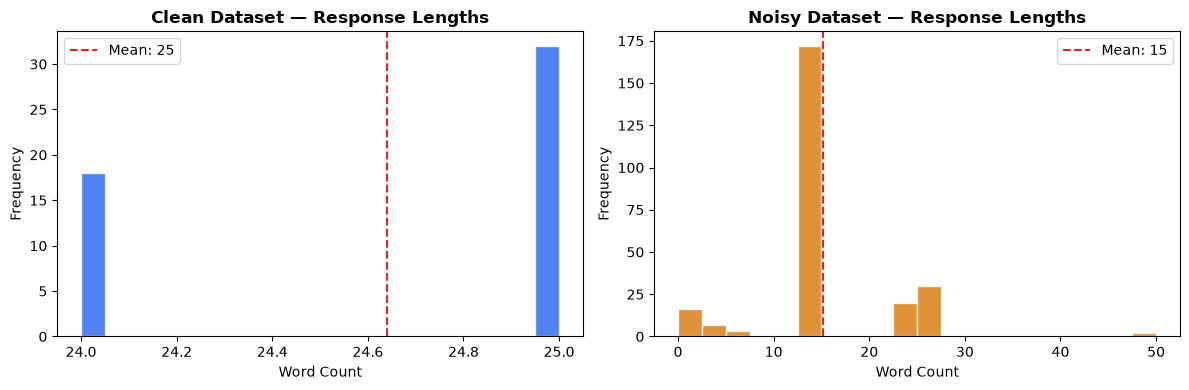


✅ Notice: Clean data has a tight, consistent distribution.
   Noisy data has a bimodal distribution with many near-zero entries.


In [5]:
# ============================================================
# 📈 Visualize Length Distributions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Clean dataset
clean_lengths = [len(d["output"].split()) for d in clean_instructions]
axes[0].hist(clean_lengths, bins=20, color="#2563eb", edgecolor="white", alpha=0.8)
axes[0].set_title("Clean Dataset — Response Lengths", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].axvline(np.mean(clean_lengths), color="#dc2626", linestyle="--", label=f"Mean: {np.mean(clean_lengths):.0f}")
axes[0].legend()

# Noisy dataset
noisy_lengths = [len(d["output"].split()) for d in noisy_instructions]
axes[1].hist(noisy_lengths, bins=20, color="#d97706", edgecolor="white", alpha=0.8)
axes[1].set_title("Noisy Dataset — Response Lengths", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")
axes[1].axvline(np.mean(noisy_lengths), color="#dc2626", linestyle="--", label=f"Mean: {np.mean(noisy_lengths):.0f}")
axes[1].legend()

plt.tight_layout()
plt.savefig("../docs/images/quality_vs_quantity_lengths.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✅ Notice: Clean data has a tight, consistent distribution.")
print("   Noisy data has a bimodal distribution with many near-zero entries.")

### 📋 Volume Guidelines by Technique

How much data do you actually need? It depends on how many parameters you're updating:

| Technique | Minimum Viable | Sweet Spot | Diminishing Returns |
|-----------|:---:|:---:|:---:|
| **Full Fine-Tuning** | 5,000 | 50,000–100,000 | >500K |
| **LoRA / DoRA** | 1,000 | 5,000–20,000 | >100K |
| **QLoRA** | 1,000 | 5,000–20,000 | >100K |
| **Prompt Tuning** | 500 | 2,000–5,000 | >20K |
| **DPO Alignment** | 1,000 pairs | 5,000–10,000 pairs | >50K pairs |
| **Distillation** | 10,000 | 50,000–200,000 | >1M |

**Why these numbers?**
- **Full FT** updates ALL parameters, so it needs more data to learn without overfitting
- **LoRA/DoRA** only updates low-rank adapters (~0.1–1% of params) → less data needed
- **Prompt Tuning** only learns a few soft tokens → even less data, but limited expressiveness
- **DPO** needs paired comparisons — each pair teaches a nuanced preference signal
- **Distillation** needs volume because you're transferring a full model's knowledge

### 💡 Rule of Thumb
> Params updated × 10 ≈ minimum training examples needed

For a LoRA adapter with 1M trainable parameters: ~1,000–10,000 examples is reasonable.

---
## Part B: Labeling Strategies

### How Do You Get Good Training Data?

There are fundamentally **four approaches** to building fine-tuning datasets:

```
┌─────────────────────────────────────────────────────────────────┐
│                    DATA SOURCING STRATEGIES                       │
├─────────────┬──────────────┬──────────────────┬─────────────────┤
│   Human     │  Synthetic   │  Self-Instruct   │    Hybrid       │
│ Annotation  │ Generation   │  / Evol-Instruct │   Approaches    │
├─────────────┼──────────────┼──────────────────┼─────────────────┤
│ • Gold std  │ • Scalable   │ • Automated      │ • Best of both  │
│ • Expensive │ • Cheap      │ • Complexity ↑   │ • Seed → expand │
│ • Slow      │ • Bias risk  │ • Diversity ↑    │ • Filter → keep │
│ • Limited   │ • Fast       │ • Programmatic   │ • Validate      │
└─────────────┴──────────────┴──────────────────┴─────────────────┘
```

### 1. Human Annotation
**When**: You need ground-truth quality (medical, legal, safety-critical applications)

Best practices:
- **Annotation guidelines**: Write explicit rules with edge cases before annotating
- **Inter-annotator agreement**: Use Cohen's Kappa ≥ 0.7 as quality threshold
- **Quality control**: 10–20% overlap between annotators for agreement checks
- **Iterative refinement**: Pilot → review → refine guidelines → annotate at scale

### 2. Synthetic Data Generation
**When**: You need scale and human annotation is too expensive

Using a larger model (GPT-4, Claude) to generate training data for a smaller one:

In [6]:
# ============================================================
# 🤖 Synthetic Data Generation Demo
# ============================================================
# In practice, you'd call a larger model's API. Here we'll simulate
# the pattern with template-based generation to show the workflow.

def generate_synthetic_instruction_data(
    seed_topics: list,
    num_per_topic: int = 3,
    complexity_levels: list = ["basic", "intermediate", "advanced"]
) -> list:
    """
    Simulate synthetic data generation pipeline.
    In production, replace the templates with API calls to GPT-4/Claude.
    """
    templates = {
        "basic": [
            "What is {topic}?",
            "Define {topic} in one sentence.",
            "Give a simple example of {topic}.",
        ],
        "intermediate": [
            "Explain how {topic} works in the context of deep learning.",
            "Compare {topic} with its alternatives.",
            "What are the trade-offs of using {topic}?",
        ],
        "advanced": [
            "Derive the mathematical formulation of {topic} and explain each term.",
            "How would you implement {topic} from scratch in PyTorch?",
            "Critique the limitations of {topic} and propose improvements.",
        ],
    }
    
    response_templates = {
        "basic": "{topic} is a technique used in machine learning for improving model performance through specialized training procedures.",
        "intermediate": "{topic} works by modifying the model's behavior during training. Compared to alternatives, it offers a balance between computational cost and effectiveness. Key trade-offs include memory usage vs. quality improvement.",
        "advanced": "The mathematical formulation of {topic} involves optimizing L(θ) = E[loss(f_θ(x), y)] subject to regularization constraints. Implementation requires careful handling of gradient computation, memory management, and numerical stability.",
    }
    
    synthetic_data = []
    for topic in seed_topics:
        for level in complexity_levels[:num_per_topic]:
            instruction = random.choice(templates[level]).format(topic=topic)
            response = response_templates[level].format(topic=topic)
            synthetic_data.append({
                "instruction": instruction,
                "output": response,
                "complexity": level,
                "topic": topic,
                "source": "synthetic",
            })
    
    return synthetic_data

# Generate synthetic data
topics = ["LoRA", "quantization", "attention", "fine-tuning", "tokenization"]
synthetic_data = generate_synthetic_instruction_data(topics)

print(f"🤖 Generated {len(synthetic_data)} synthetic examples")
print(f"\n--- Example (basic) ---")
ex = [d for d in synthetic_data if d["complexity"] == "basic"][0]
print(f"Q: {ex['instruction']}")
print(f"A: {ex['output']}")
print(f"\n--- Example (advanced) ---")
ex = [d for d in synthetic_data if d["complexity"] == "advanced"][0]
print(f"Q: {ex['instruction']}")
print(f"A: {ex['output'][:150]}...")

🤖 Generated 15 synthetic examples

--- Example (basic) ---
Q: What is LoRA?
A: LoRA is a technique used in machine learning for improving model performance through specialized training procedures.

--- Example (advanced) ---
Q: How would you implement LoRA from scratch in PyTorch?
A: The mathematical formulation of LoRA involves optimizing L(θ) = E[loss(f_θ(x), y)] subject to regularization constraints. Implementation requires care...


In [7]:
# ============================================================
# 🔍 Filtering Synthetic Data
# ============================================================
# Not all synthetic data is good. Here are three filtering strategies:

def filter_by_rules(data: list) -> list:
    """Rule-based filtering: remove obviously bad examples."""
    filtered = []
    for ex in data:
        response = ex["output"]
        # Rule 1: Response must be non-empty
        if not response.strip():
            continue
        # Rule 2: Response must be at least 10 words
        if len(response.split()) < 10:
            continue
        # Rule 3: No excessive repetition
        words = response.split()
        if len(set(words)) / len(words) < 0.3:  # >70% repeated words
            continue
        # Rule 4: Must not be a refusal
        refusal_phrases = ["I cannot", "I'm unable", "As an AI"]
        if any(phrase.lower() in response.lower() for phrase in refusal_phrases):
            continue
        filtered.append(ex)
    return filtered

def filter_by_length_percentile(data: list, min_pct: int = 10, max_pct: int = 95) -> list:
    """Remove statistical outliers by length."""
    lengths = [len(d["output"].split()) for d in data]
    min_len = np.percentile(lengths, min_pct)
    max_len = np.percentile(lengths, max_pct)
    return [d for d in data if min_len <= len(d["output"].split()) <= max_len]

# Apply filters
print("📊 Filtering pipeline:")
print(f"   Raw synthetic data: {len(synthetic_data)} examples")

after_rules = filter_by_rules(synthetic_data)
print(f"   After rule-based filter: {len(after_rules)} examples")

after_length = filter_by_length_percentile(after_rules)
print(f"   After length filter: {len(after_length)} examples")

print(f"\n✅ Retained {len(after_length)/len(synthetic_data)*100:.0f}% of synthetic data")
print("\n💡 In production, you'd also use:")
print("   • Perplexity-based filtering (remove low-confidence generations)")
print("   • Model-as-judge (use another LLM to rate quality)")
print("   • Embedding deduplication (remove near-duplicates)")

📊 Filtering pipeline:
   Raw synthetic data: 15 examples
   After rule-based filter: 15 examples
   After length filter: 15 examples

✅ Retained 100% of synthetic data

💡 In production, you'd also use:
   • Perplexity-based filtering (remove low-confidence generations)
   • Model-as-judge (use another LLM to rate quality)
   • Embedding deduplication (remove near-duplicates)


### 3. Self-Instruct / Evol-Instruct

These are techniques for **programmatically increasing complexity** of training data:

**Self-Instruct** (Wang et al., 2022):
1. Start with a small seed set of instructions
2. Use the model itself to generate new instructions
3. Filter and validate → add to training set
4. Repeat

**Evol-Instruct** (Xu et al., 2023, used in WizardLM):
1. Start with simple instructions
2. Apply evolution operators:
   - **Add constraints**: "Sort a list" → "Sort a list of objects by multiple keys with tie-breaking"
   - **Deepen**: "What is X?" → "Explain X, its history, variants, and current research directions"
   - **Concretize**: "Write code" → "Write a Python function that handles edge cases and has type hints"
   - **Increase reasoning**: "Calculate X" → "Prove why X follows from axioms A, B, C"
3. Filter for quality and diversity
4. Result: harder, more diverse training data

### 4. When NOT to Use Synthetic Data

⚠️ **Domains where factual accuracy is critical:**
- **Medical**: Synthetic data may hallucinate drug interactions, dosages, or diagnoses
- **Legal**: Generated case law or statutes may not exist
- **Financial**: Fabricated numbers in financial analysis can be dangerous
- **Scientific**: Made-up citations or experimental results

In these domains, use human-curated data with expert validation.

---
## Part C: Data Governance & Licensing

### 📜 Why This Matters (More Than You Think)

Training on the wrong data can expose you to:
- **Legal liability** (copyright infringement, license violations)
- **Privacy violations** (GDPR, HIPAA, CCPA fines)
- **Reputational damage** (model leaks PII, biased outputs)

### License Compatibility Matrix

| License | Commercial Use | Modification | Distribution | Patent Grant | Risk Level |
|---------|:---:|:---:|:---:|:---:|:---:|
| **MIT** | ✅ | ✅ | ✅ | ❌ | 🟢 Low |
| **Apache 2.0** | ✅ | ✅ | ✅ | ✅ | 🟢 Low |
| **CC-BY 4.0** | ✅ | ✅ | ✅ (with attribution) | N/A | 🟢 Low |
| **CC-BY-NC** | ❌ | ✅ | ✅ (non-commercial) | N/A | 🟡 Medium |
| **GPL 3.0** | ✅ | ✅ | ✅ (copyleft!) | ✅ | 🟡 Medium |
| **Proprietary** | ❌ | ❌ | ❌ | ❌ | 🔴 High |
| **Web-scraped** | ❓ | ❓ | ❓ | N/A | 🔴 High |

### Key Considerations
- **Code datasets**: Check license compatibility (the GitHub Copilot controversy showed this matters)
- **Medical data**: HIPAA requires de-identification; consider synthetic alternatives
- **Web-scraped data**: Check robots.txt, copyright status, opt-out mechanisms
- **Model outputs as training data**: Check the API ToS (e.g., OpenAI restricts using outputs to train competing models)

### 🔒 Privacy & PII Detection

Before fine-tuning, you MUST scrub Personally Identifiable Information (PII) from your data:

In [10]:
# ============================================================
# 🔒 PII Detection Demo
# ============================================================
# We'll use regex-based detection for common PII patterns.
# In production, use a library like Presidio, spaCy NER, or AWS Comprehend.

import re

# Common PII patterns (using raw strings with explicit word boundaries)
PII_PATTERNS = {
    "email": r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}',
    "phone_us": r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b',
    "ssn": r'\b\d{3}-\d{2}-\d{4}\b',
    "credit_card": r'\b\d{4}[-\s]?\d{4}[-\s]?\d{4}[-\s]?\d{4}\b',
    "ip_address": r'\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b',
    "date_of_birth": r'\b(0[1-9]|1[0-2])/(0[1-9]|[12]\d|3[01])/\d{4}\b',
}

def detect_pii(text: str) -> dict:
    """Detect PII patterns in text. Returns dict of found PII types and counts."""
    findings = {}
    for pii_type, pattern in PII_PATTERNS.items():
        matches = re.findall(pattern, text)
        if matches:
            # date_of_birth has groups → re.findall returns tuples; reconstruct full match
            if pii_type == "date_of_birth":
                full_matches = re.findall(
                    r'\b(?:0[1-9]|1[0-2])/(?:0[1-9]|[12]\d|3[01])/\d{4}\b', text
                )
                findings[pii_type] = {"count": len(full_matches), "examples": full_matches[:2]}
            else:
                findings[pii_type] = {"count": len(matches), "examples": matches[:2]}
    return findings

def scrub_pii(text: str) -> str:
    """Replace detected PII with redaction tokens."""
    redacted = text
    replacements = {
        "email": "[EMAIL_REDACTED]",
        "phone_us": "[PHONE_REDACTED]",
        "ssn": "[SSN_REDACTED]",
        "credit_card": "[CC_REDACTED]",
        "ip_address": "[IP_REDACTED]",
        "date_of_birth": "[DOB_REDACTED]",
    }
    # Use plain (non-capturing) versions for scrubbing
    scrub_patterns = {
        "email": r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}',
        "phone_us": r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b',
        "ssn": r'\b\d{3}-\d{2}-\d{4}\b',
        "credit_card": r'\b\d{4}[-\s]?\d{4}[-\s]?\d{4}[-\s]?\d{4}\b',
        "ip_address": r'\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b',
        "date_of_birth": r'\b(?:0[1-9]|1[0-2])/(?:0[1-9]|[12]\d|3[01])/\d{4}\b',
    }
    for pii_type, pattern in scrub_patterns.items():
        redacted = re.sub(pattern, replacements[pii_type], redacted)
    return redacted

# Test with synthetic PII examples (all fake!)
test_texts = [
    "Contact John at john.doe@example.com or call 555-123-4567.",
    "Patient SSN: 123-45-6789, DOB: 03/15/1985. Diagnosis: Type 2 diabetes.",
    "Payment processed for card 4532-1234-5678-9012 from IP 192.168.1.100.",
    "The algorithm uses gradient descent with learning rate 0.001.",  # No PII
]

print("🔍 PII Detection Results:")
print("=" * 60)
for text in test_texts:
    findings = detect_pii(text)
    if findings:
        print(f"\n⚠️  TEXT: '{text[:60]}...'")
        for pii_type, info in findings.items():
            print(f"   Found {pii_type}: {info['count']} instance(s)")
        print(f"   🧹 Scrubbed: '{scrub_pii(text)[:80]}...'")
    else:
        print(f"\n✅ TEXT: '{text[:60]}' — No PII detected")


🔍 PII Detection Results:

⚠️  TEXT: 'Contact John at john.doe@example.com or call 555-123-4567....'
   Found email: 1 instance(s)
   Found phone_us: 1 instance(s)
   🧹 Scrubbed: 'Contact John at [EMAIL_REDACTED] or call [PHONE_REDACTED]....'

⚠️  TEXT: 'Patient SSN: 123-45-6789, DOB: 03/15/1985. Diagnosis: Type 2...'
   Found ssn: 1 instance(s)
   Found date_of_birth: 1 instance(s)
   🧹 Scrubbed: 'Patient SSN: [SSN_REDACTED], DOB: [DOB_REDACTED]. Diagnosis: Type 2 diabetes....'

⚠️  TEXT: 'Payment processed for card 4532-1234-5678-9012 from IP 192.1...'
   Found credit_card: 1 instance(s)
   Found ip_address: 1 instance(s)
   🧹 Scrubbed: 'Payment processed for card [CC_REDACTED] from IP [IP_REDACTED]....'

✅ TEXT: 'The algorithm uses gradient descent with learning rate 0.001' — No PII detected


In [11]:
# ============================================================
# 📊 Scan a Dataset for PII Before Training
# ============================================================

def audit_dataset_for_pii(data: list, text_key: str = "output") -> dict:
    """Scan entire dataset for PII. Returns summary report."""
    total_pii_found = 0
    contaminated_examples = 0
    pii_type_counts = Counter()
    
    for example in data:
        text = example.get(text_key, "")
        findings = detect_pii(text)
        if findings:
            contaminated_examples += 1
            for pii_type, info in findings.items():
                total_pii_found += info["count"]
                pii_type_counts[pii_type] += info["count"]
    
    return {
        "total_examples": len(data),
        "contaminated_examples": contaminated_examples,
        "contamination_rate": contaminated_examples / len(data) * 100,
        "total_pii_instances": total_pii_found,
        "pii_by_type": dict(pii_type_counts),
    }

# Create a dataset with some PII "contamination" (all fake data!)
contaminated_dataset = [
    {"instruction": "Summarize this patient record",
     "output": "Patient Jane Smith (SSN: 987-65-4321) presented with symptoms..."},
    {"instruction": "Write a customer service email",
     "output": "Dear user, your account jane@company.com has been updated. Call 555-987-6543 for help."},
    {"instruction": "What is machine learning?",
     "output": "Machine learning is a subset of AI that enables systems to learn from data."},
    {"instruction": "Explain transformers",
     "output": "Transformers use self-attention to process sequences in parallel."},
    {"instruction": "Draft an invoice",
     "output": "Invoice for: Bob Johnson, Card: 4111-1111-1111-1111, Amount: $500."},
] * 10  # Repeat to simulate a larger dataset

report = audit_dataset_for_pii(contaminated_dataset)
print("🔒 PII Audit Report:")
print("=" * 60)
print(f"   Total examples scanned: {report['total_examples']}")
print(f"   Contaminated examples: {report['contaminated_examples']}")
print(f"   Contamination rate: {report['contamination_rate']:.1f}%")
print(f"   Total PII instances: {report['total_pii_instances']}")
print(f"\n   PII by type:")
for pii_type, count in report["pii_by_type"].items():
    print(f"     • {pii_type}: {count}")
print(f"\n⚠️  ACTION REQUIRED: Scrub PII before training!")
print("   Use scrub_pii() on all text fields, or filter contaminated examples.")

🔒 PII Audit Report:
   Total examples scanned: 50
   Contaminated examples: 30
   Contamination rate: 60.0%
   Total PII instances: 40

   PII by type:
     • ssn: 10
     • email: 10
     • phone_us: 10
     • credit_card: 10

⚠️  ACTION REQUIRED: Scrub PII before training!
   Use scrub_pii() on all text fields, or filter contaminated examples.


### 📋 Reproducibility Checklist

Every fine-tuning dataset should have a **data card** documenting:

1. **Source**: Where did this data come from?
2. **License**: What license governs its use?
3. **Size**: How many examples? What's the token distribution?
4. **Quality process**: How was it curated/filtered?
5. **Known limitations**: Biases, gaps, failure modes?
6. **Version**: Dataset version hash for reproducibility
7. **PII status**: Has it been audited and scrubbed?

### 🔍 Bias Audit

Before training, check your data for:
- **Demographic imbalance**: Does it represent diverse viewpoints?
- **Toxicity**: Run a toxicity classifier on responses
- **Stereotypes**: Check for harmful associations
- **Language balance**: If multilingual, is the distribution fair?

---
## Part D: Practical Implementation

Now let's get our hands dirty with the actual tools and techniques you'll use every day.

### 🔤 Tokenizer Deep Dive

Tokenizers are the bridge between text and numbers. Different tokenizer types have different strengths:

| Tokenizer | Used By | Strengths | Weaknesses |
|-----------|---------|-----------|------------|
| **BPE** (Byte Pair Encoding) | GPT, LLaMA, SmolLM | Good compression, handles rare words | Fixed vocabulary |
| **WordPiece** | BERT, DistilBERT | Handles OOV with ##subwords | Less efficient than BPE |
| **SentencePiece** | T5, mBART, Qwen | Language-agnostic, raw text input | Slightly slower |
| **Unigram** | XLNet, ALBERT | Probabilistic, good for multilingual | Rare in modern LLMs |

Let's compare how different tokenizers handle the same text:

In [12]:
# ============================================================
# 🔤 Tokenizer Comparison
# ============================================================
from transformers import AutoTokenizer

# Load tokenizers from our target models
tokenizers_to_compare = {
    "SmolLM2-135M": "HuggingFaceTB/SmolLM2-135M-Instruct",
    "Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
}

# Test sentences with different characteristics
test_sentences = [
    "The quick brown fox jumps over the lazy dog.",  # Simple English
    "Fine-tuning a 135M parameter model with LoRA on 8-bit quantization.",  # Technical
    "def fibonacci(n): return n if n <= 1 else fibonacci(n-1) + fibonacci(n-2)",  # Code
    "🎉 Congratulations! Your model achieved 95.2% accuracy! 🚀",  # Emoji + numbers
]

print("🔤 Tokenizer Comparison")
print("=" * 70)

results = {}
for name, model_id in tokenizers_to_compare.items():
    try:
        tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
        results[name] = []
        print(f"\n{'─'*70}")
        print(f"📦 {name} (vocab size: {tok.vocab_size:,})")
        print(f"{'─'*70}")
        for sent in test_sentences:
            tokens = tok.encode(sent)
            decoded_tokens = [tok.decode([t]) for t in tokens]
            results[name].append(len(tokens))
            print(f"\n  Input ({len(sent)} chars): '{sent[:50]}{'...' if len(sent)>50 else ''}'")
            print(f"  Tokens ({len(tokens)}): {decoded_tokens[:10]}{'...' if len(tokens)>10 else ''}")
    except Exception as e:
        print(f"  ⚠️ Could not load {name}: {e}")
        results[name] = [0] * len(test_sentences)

🔤 Tokenizer Comparison



──────────────────────────────────────────────────────────────────────
📦 SmolLM2-135M (vocab size: 49,152)
──────────────────────────────────────────────────────────────────────

  Input (44 chars): 'The quick brown fox jumps over the lazy dog.'
  Tokens (10): ['The', ' quick', ' brown', ' fox', ' jumps', ' over', ' the', ' lazy', ' dog', '.']

  Input (67 chars): 'Fine-tuning a 135M parameter model with LoRA on 8-...'
  Tokens (22): ['Fine', '-', 'tuning', ' a', ' ', '1', '3', '5', 'M', ' parameter']...

  Input (73 chars): 'def fibonacci(n): return n if n <= 1 else fibonacc...'
  Tokens (29): ['def', ' fib', 'onacci', '(', 'n', '):', ' return', ' n', ' if', ' n']...

  Input (56 chars): '🎉 Congratulations! Your model achieved 95.2% accur...'
  Tokens (19): ['�', '�', '�', ' Congratulations', '!', ' Your', ' model', ' achieved', ' ', '9']...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


──────────────────────────────────────────────────────────────────────
📦 Qwen2.5-1.5B (vocab size: 151,643)
──────────────────────────────────────────────────────────────────────

  Input (44 chars): 'The quick brown fox jumps over the lazy dog.'
  Tokens (10): ['The', ' quick', ' brown', ' fox', ' jumps', ' over', ' the', ' lazy', ' dog', '.']

  Input (67 chars): 'Fine-tuning a 135M parameter model with LoRA on 8-...'
  Tokens (21): ['Fine', '-t', 'uning', ' a', ' ', '1', '3', '5', 'M', ' parameter']...

  Input (73 chars): 'def fibonacci(n): return n if n <= 1 else fibonacc...'
  Tokens (23): ['def', ' fibonacci', '(n', '):', ' return', ' n', ' if', ' n', ' <=', ' ']...

  Input (56 chars): '🎉 Congratulations! Your model achieved 95.2% accur...'
  Tokens (17): ['🎉', ' Congratulations', '!', ' Your', ' model', ' achieved', ' ', '9', '5', '.']...


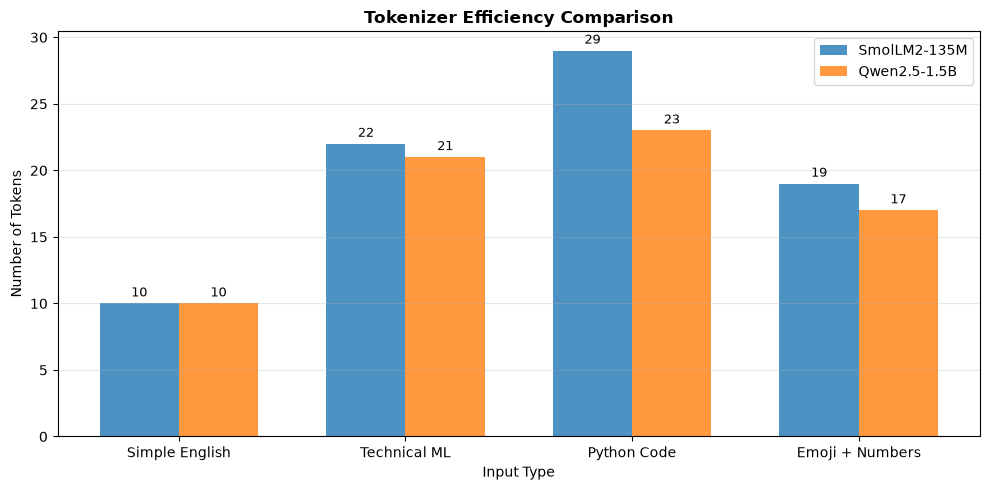


💡 Key takeaways:
   • Larger vocabularies → fewer tokens for same text → more efficient
   • Code and special characters often need more tokens
   • Tokenizer choice affects max context window utilization


In [13]:
# ============================================================
# 📊 Visualize Tokenizer Efficiency
# ============================================================

if results:
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(test_sentences))
    width = 0.35
    
    labels = ["Simple English", "Technical ML", "Python Code", "Emoji + Numbers"]
    
    for i, (name, token_counts) in enumerate(results.items()):
        offset = (i - len(results)/2 + 0.5) * width
        bars = ax.bar(x + offset, token_counts, width, label=name, alpha=0.8)
        for bar, count in zip(bars, token_counts):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    str(count), ha='center', va='bottom', fontsize=9)
    
    ax.set_xlabel("Input Type")
    ax.set_ylabel("Number of Tokens")
    ax.set_title("Tokenizer Efficiency Comparison", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig("../docs/images/tokenizer_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    
    print("\n💡 Key takeaways:")
    print("   • Larger vocabularies → fewer tokens for same text → more efficient")
    print("   • Code and special characters often need more tokens")
    print("   • Tokenizer choice affects max context window utilization")

### 💬 Chat Template Formatting

Different models expect different chat formats. Using the **wrong template** is the #1 cause of garbled fine-tuned model output (we'll demonstrate this in Failure Point #1).

Here are the major formats:

#### ChatML (used by Qwen, many modern models)
```
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Hello!<|im_end|>
<|im_start|>assistant
Hi there! How can I help?<|im_end|>
```

#### SmolLM / Llama Style
```
<|system|>
You are a helpful assistant.</s>
<|user|>
Hello!</s>
<|assistant|>
Hi there! How can I help?</s>
```

#### Alpaca Format (legacy, for reference)
```
### Instruction:
Hello!

### Response:
Hi there! How can I help?
```

**The critical rule**: Always use `tokenizer.apply_chat_template()` — it knows the correct format for each model.

In [14]:
# ============================================================
# 💬 Chat Template Demonstration
# ============================================================

messages = [
    {"role": "system", "content": "You are a helpful coding assistant."},
    {"role": "user", "content": "Write a Python function to calculate factorial."},
    {"role": "assistant", "content": "Here's a recursive factorial function:\n\ndef factorial(n):\n    if n <= 1:\n        return 1\n    return n * factorial(n - 1)"},
]

print("💬 Chat Template Comparison")
print("=" * 70)

for name, model_id in tokenizers_to_compare.items():
    try:
        tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
        formatted = tok.apply_chat_template(messages, tokenize=False)
        print(f"\n{'─'*70}")
        print(f"📦 {name} format:")
        print(f"{'─'*70}")
        print(formatted[:500])
        print(f"\n  → Total tokens: {len(tok.encode(formatted))}")
    except Exception as e:
        print(f"  ⚠️ {name}: {e}")

💬 Chat Template Comparison

──────────────────────────────────────────────────────────────────────
📦 SmolLM2-135M format:
──────────────────────────────────────────────────────────────────────
<|im_start|>system
You are a helpful coding assistant.<|im_end|>
<|im_start|>user
Write a Python function to calculate factorial.<|im_end|>
<|im_start|>assistant
Here's a recursive factorial function:

def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)<|im_end|>


  → Total tokens: 71

──────────────────────────────────────────────────────────────────────
📦 Qwen2.5-1.5B format:
──────────────────────────────────────────────────────────────────────
<|im_start|>system
You are a helpful coding assistant.<|im_end|>
<|im_start|>user
Write a Python function to calculate factorial.<|im_end|>
<|im_start|>assistant
Here's a recursive factorial function:

def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)<|im_end|>


  → Total tokens: 63


### 📂 Loading Datasets from HuggingFace Hub

Let's load real datasets and examine their structure. We'll use two popular instruction-tuning datasets:

- **databricks/dolly-15k**: Human-generated instruction/response pairs (15K examples)
- **tatsu-lab/alpaca**: GPT-generated instruction data (52K examples)

In [15]:
# ============================================================
# 📂 Load and Explore Real Datasets
# ============================================================
from data_utils import load_and_format_dataset, compute_dataset_statistics, check_data_quality

# Load Dolly dataset (human-written)
print("📥 Loading databricks/dolly-15k...")
dolly = load_and_format_dataset("databricks/dolly-15k", split="train", max_samples=500)
print(f"   Loaded: {len(dolly)} examples")
print(f"   Columns: {dolly.column_names}")
print(f"\n   Example:")
print(f"   Category: {dolly[0].get('category', 'N/A')}")
print(f"   Instruction: {dolly[0]['instruction'][:100]}...")
print(f"   Response: {dolly[0]['response'][:100]}...")

print(f"\n{'='*60}")

# Load Alpaca dataset (synthetic, GPT-generated)
print("\n📥 Loading tatsu-lab/alpaca...")
alpaca = load_and_format_dataset("tatsu-lab/alpaca", split="train", max_samples=500)
print(f"   Loaded: {len(alpaca)} examples")
print(f"   Columns: {alpaca.column_names}")
print(f"\n   Example:")
print(f"   Instruction: {alpaca[0]['instruction'][:100]}...")
print(f"   Output: {alpaca[0]['output'][:100]}...")

📥 Loading databricks/dolly-15k...
   Loaded: 240 examples
   Columns: ['category', 'instruction', 'response', 'output']

   Example:
   Category: open_qa
   Instruction: Explain what fine-tuning means for a language model in the context of instruction tuning....
   Response: Fine-tuning adapts a pre-trained model to instruction tuning by continuing training on task-specific...


📥 Loading tatsu-lab/alpaca...


README.md:   0%|          | 0.00/7.47k [00:00<?, ?B/s]

data/train-00000-of-00001-a09b74b3ef9c3b(…):   0%|          | 0.00/24.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]

   Loaded: 500 examples
   Columns: ['instruction', 'input', 'output', 'text']

   Example:
   Instruction: Give three tips for staying healthy....
   Output: 1.Eat a balanced diet and make sure to include plenty of fruits and vegetables. 
2. Exercise regular...


In [16]:
# ============================================================
# 📊 Dataset Quality Analysis
# ============================================================

def analyze_real_dataset(dataset, name: str, text_column: str):
    """Comprehensive quality analysis of a HuggingFace dataset."""
    texts = dataset[text_column]
    lengths = [len(t.split()) for t in texts if t]
    
    print(f"\n📊 {name} Quality Report")
    print("─" * 50)
    print(f"   Total examples: {len(dataset)}")
    print(f"   Average length: {np.mean(lengths):.0f} words")
    print(f"   Median length: {np.median(lengths):.0f} words")
    print(f"   Min/Max: {min(lengths)}/{max(lengths)} words")
    print(f"   Std dev: {np.std(lengths):.0f} words")
    
    # Check for issues
    empty = sum(1 for t in texts if not t or not t.strip())
    very_short = sum(1 for t in texts if t and len(t.split()) < 3)
    print(f"   Empty entries: {empty}")
    print(f"   Very short (<3 words): {very_short}")
    
    return lengths

# Analyze both datasets
dolly_response_col = "response" if "response" in dolly.column_names else "output"
alpaca_response_col = "output" if "output" in alpaca.column_names else "response"

dolly_lengths = analyze_real_dataset(dolly, "Dolly-15k (Human)", dolly_response_col)
alpaca_lengths = analyze_real_dataset(alpaca, "Alpaca (Synthetic)", alpaca_response_col)


📊 Dolly-15k (Human) Quality Report
──────────────────────────────────────────────────
   Total examples: 240
   Average length: 15 words
   Median length: 18 words
   Min/Max: 1/19 words
   Std dev: 7 words
   Empty entries: 0
   Very short (<3 words): 48

📊 Alpaca (Synthetic) Quality Report
──────────────────────────────────────────────────
   Total examples: 500
   Average length: 40 words
   Median length: 20 words
   Min/Max: 1/322 words
   Std dev: 45 words
   Empty entries: 1
   Very short (<3 words): 43


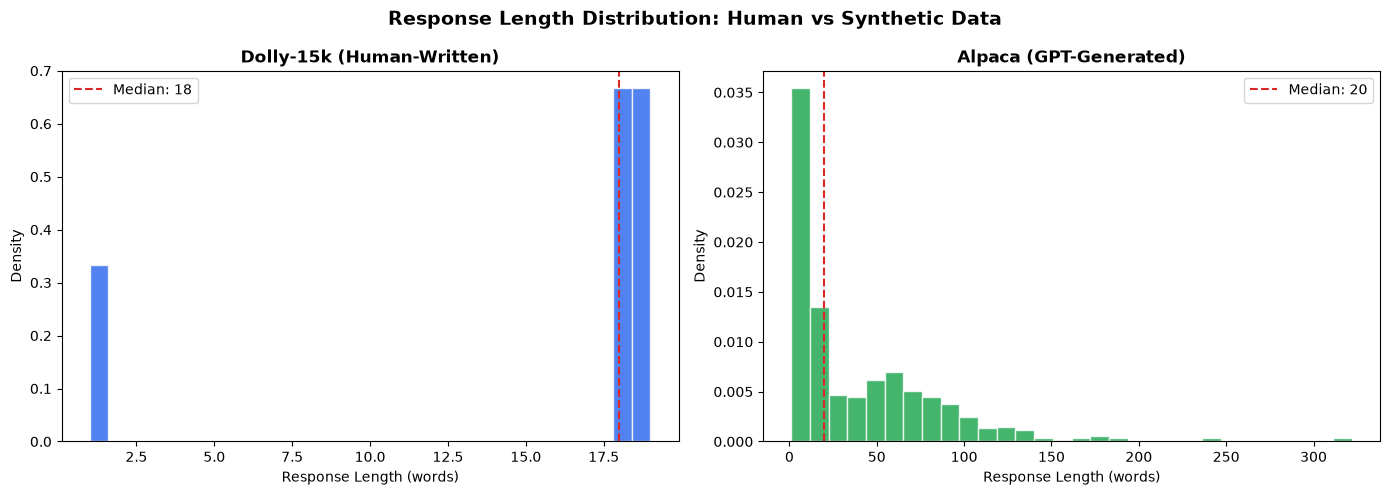


💡 Observations:
   • Human-written (Dolly) has more varied lengths — natural diversity
   • Synthetic (Alpaca) tends toward more uniform, medium-length responses
   • Both patterns are useful — depends on your objective!


In [17]:
# ============================================================
# 📈 Compare Length Distributions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dolly
axes[0].hist(dolly_lengths, bins=30, color="#2563eb", edgecolor="white", alpha=0.8, density=True)
axes[0].axvline(np.median(dolly_lengths), color="#dc2626", linestyle="--", 
                label=f"Median: {np.median(dolly_lengths):.0f}")
axes[0].set_title("Dolly-15k (Human-Written)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Response Length (words)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Alpaca
axes[1].hist(alpaca_lengths, bins=30, color="#16a34a", edgecolor="white", alpha=0.8, density=True)
axes[1].axvline(np.median(alpaca_lengths), color="#dc2626", linestyle="--", 
                label=f"Median: {np.median(alpaca_lengths):.0f}")
axes[1].set_title("Alpaca (GPT-Generated)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Response Length (words)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.suptitle("Response Length Distribution: Human vs Synthetic Data", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../docs/images/dataset_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n💡 Observations:")
print("   • Human-written (Dolly) has more varied lengths — natural diversity")
print("   • Synthetic (Alpaca) tends toward more uniform, medium-length responses")
print("   • Both patterns are useful — depends on your objective!")

In [18]:
# ============================================================
# ✅ Data Quality Checks
# ============================================================
# Using our src/data_utils.py quality checking utility

# For Dolly, rename column to "text" for our utility
dolly_for_check = dolly.map(lambda x: {"text": x[dolly_response_col]})
quality_report = check_data_quality(dolly_for_check, text_column="text")

print("✅ Data Quality Check (Dolly-15k sample):")
print("─" * 50)
print(f"   Total entries: {quality_report['total']}")
print(f"   Unique entries: {quality_report['unique']}")
print(f"   Empty entries: {quality_report['empty']}")
if quality_report['issues']:
    print(f"\n   ⚠️ Issues found:")
    for issue in quality_report['issues']:
        print(f"      • {issue}")
else:
    print(f"\n   ✅ No issues found!")

print(f"\n📊 Deduplication ratio: {quality_report['unique']/quality_report['total']*100:.1f}%")

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

✅ Data Quality Check (Dolly-15k sample):
──────────────────────────────────────────────────
   Total entries: 240
   Unique entries: 9
   Empty entries: 0

   ⚠️ Issues found:
      • Found 231 duplicate entries

📊 Deduplication ratio: 3.8%


In [19]:
# ============================================================
# ✂️ Train / Validation / Test Splitting
# ============================================================
# For fine-tuning, standard splits differ from traditional ML:
#
# Traditional ML: 70/15/15 or 80/10/10
# Fine-tuning:    90/5/5 or 95/2.5/2.5 (data is precious!)
#
# Key principle: Your test set should be REPRESENTATIVE of deployment use.

from datasets import DatasetDict

def create_finetuning_splits(
    dataset, 
    train_pct: float = 0.9, 
    val_pct: float = 0.05, 
    seed: int = 42
) -> DatasetDict:
    """Create train/val/test splits optimized for fine-tuning."""
    # First split: train + rest
    train_test = dataset.train_test_split(test_size=1-train_pct, seed=seed)
    
    # Second split: val + test from the rest
    val_test_ratio = val_pct / (1 - train_pct)  # proportion of val within remaining
    val_test = train_test["test"].train_test_split(test_size=0.5, seed=seed)
    
    splits = DatasetDict({
        "train": train_test["train"],
        "validation": val_test["train"],
        "test": val_test["test"],
    })
    return splits

# Create splits from our Dolly sample
splits = create_finetuning_splits(dolly)
print("✂️ Fine-Tuning Data Splits:")
print("─" * 50)
for split_name, split_data in splits.items():
    print(f"   {split_name:12s}: {len(split_data):4d} examples ({len(split_data)/len(dolly)*100:.1f}%)")

print(f"\n💡 Tips for splitting fine-tuning data:")
print("   • Keep test set small but representative")
print("   • Stratify by category/difficulty if possible")
print("   • NEVER let test examples leak into training")
print("   • Consider temporal splits if data has timestamps")

✂️ Fine-Tuning Data Splits:
──────────────────────────────────────────────────
   train       :  216 examples (90.0%)
   validation  :   12 examples (5.0%)
   test        :   12 examples (5.0%)

💡 Tips for splitting fine-tuning data:
   • Keep test set small but representative
   • Stratify by category/difficulty if possible
   • NEVER let test examples leak into training
   • Consider temporal splits if data has timestamps


In [20]:
# ============================================================
# 🔧 Format Dataset for Training (Using Chat Templates)
# ============================================================
from data_utils import apply_chat_template

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Prepare Alpaca data for chat template formatting
# Our apply_chat_template expects "instruction" and "output" columns
alpaca_subset = alpaca.select(range(min(50, len(alpaca))))

system_prompt = "You are a helpful, concise assistant."

# Apply chat template using our utility
formatted = alpaca_subset.map(
    lambda examples: apply_chat_template(examples, tokenizer, system_prompt),
    batched=True,
    batch_size=10,
    remove_columns=alpaca_subset.column_names,
)

print("🔧 Formatted Dataset for Training:")
print("─" * 50)
print(f"   Examples: {len(formatted)}")
print(f"   Columns: {formatted.column_names}")
print(f"\n   First example (formatted with chat template):")
print(f"   {formatted[0]['text'][:300]}...")

# Check token lengths
token_lengths = [len(tokenizer.encode(t)) for t in formatted["text"]]
print(f"\n📊 Token length statistics:")
print(f"   Mean: {np.mean(token_lengths):.0f} tokens")
print(f"   Max: {max(token_lengths)} tokens")
print(f"   Min: {min(token_lengths)} tokens")
print(f"\n💡 Max sequence length for training should be >= {int(np.percentile(token_lengths, 95))} (95th percentile)")

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

🔧 Formatted Dataset for Training:
──────────────────────────────────────────────────
   Examples: 50
   Columns: ['text']

   First example (formatted with chat template):
   <|im_start|>system
You are a helpful, concise assistant.<|im_end|>
<|im_start|>user
Give three tips for staying healthy.<|im_end|>
<|im_start|>assistant
1.Eat a balanced diet and make sure to include plenty of fruits and vegetables. 
2. Exercise regularly to keep your body active and strong. 
3. Get...

📊 Token length statistics:
   Mean: 111 tokens
   Max: 323 tokens
   Min: 32 tokens

💡 Max sequence length for training should be >= 242 (95th percentile)


---
## 🔴 Failure Point #1: Wrong Chat Template → Garbled Output

### The Problem

One of the most common and frustrating bugs in fine-tuning: you train a model, it converges nicely (loss goes down!), but then generates complete garbage at inference time.

**Root cause**: The model was trained with one chat template format but you're prompting it with a different one (or no template at all).

### Why This Happens
- You format training data as raw text but inference uses `apply_chat_template()`
- You use Alpaca format for a model trained on ChatML
- You forget the system prompt that was in training
- You accidentally include/exclude special tokens

Let's demonstrate this failure mode and then fix it.

In [21]:
# ============================================================
# 🔴 FAILURE POINT #1: Demonstrate the Problem
# ============================================================
# We'll show what happens when you use the WRONG template format.

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)

messages = [
    {"role": "user", "content": "What is the capital of France?"},
]

# CORRECT: Use the model's built-in chat template
correct_format = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

# WRONG: Use Alpaca format (mismatched with model's expected format)
wrong_format_alpaca = f"""### Instruction:
What is the capital of France?

### Response:
"""

# WRONG: Use ChatML when model expects something else  
wrong_format_chatml = f"""<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant
"""

# WRONG: Plain text with no template at all
wrong_format_plain = "What is the capital of France?"

print("🔴 FAILURE POINT #1: Wrong Chat Template")
print("=" * 70)
print(f"\n✅ CORRECT format (model's native template):")
print(f"{'─'*50}")
print(correct_format)
print(f"\n❌ WRONG format (Alpaca style):")
print(f"{'─'*50}")
print(wrong_format_alpaca)
print(f"\n❌ WRONG format (ChatML for non-ChatML model):")
print(f"{'─'*50}")
print(wrong_format_chatml)
print(f"\n❌ WRONG format (no template):")
print(f"{'─'*50}")
print(wrong_format_plain)

🔴 FAILURE POINT #1: Wrong Chat Template

✅ CORRECT format (model's native template):
──────────────────────────────────────────────────
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant


❌ WRONG format (Alpaca style):
──────────────────────────────────────────────────
### Instruction:
What is the capital of France?

### Response:


❌ WRONG format (ChatML for non-ChatML model):
──────────────────────────────────────────────────
<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant


❌ WRONG format (no template):
──────────────────────────────────────────────────
What is the capital of France?


In [22]:
# ============================================================
# 🔴 DIAGNOSE: See the Token-Level Difference
# ============================================================
# The model literally sees different token sequences for each format.
# Let's compare what the model actually receives:

print("🔍 Token-Level Diagnosis")
print("=" * 70)

formats = {
    "✅ Correct (native)": correct_format,
    "❌ Alpaca format": wrong_format_alpaca,
    "❌ ChatML format": wrong_format_chatml,
    "❌ Plain text": wrong_format_plain,
}

for label, text in formats.items():
    tokens = tokenizer.encode(text)
    # Check for unknown/special token issues
    decoded_tokens = [tokenizer.decode([t]) for t in tokens[:15]]
    unk_count = sum(1 for t in tokens if t == tokenizer.unk_token_id) if tokenizer.unk_token_id else 0
    
    print(f"\n{label}:")
    print(f"  Token count: {len(tokens)}")
    print(f"  Unknown tokens: {unk_count}")
    print(f"  First 15 tokens: {decoded_tokens}")
    
print("\n" + "=" * 70)
print("💡 DIAGNOSIS:")
print("   • Wrong templates introduce tokens the model has never seen during training")
print("   • The model's attention patterns were learned on its native format")
print("   • Even small template differences (extra newline, wrong special token)")
print("     can shift ALL token positions and break learned patterns")

🔍 Token-Level Diagnosis

✅ Correct (native):
  Token count: 37
  Unknown tokens: 0
  First 15 tokens: ['<|im_start|>', 'system', '\n', 'You', ' are', ' a', ' helpful', ' AI', ' assistant', ' named', ' Sm', 'ol', 'LM', ',', ' trained']

❌ Alpaca format:
  Token count: 17
  Unknown tokens: 0
  First 15 tokens: ['###', ' Instruction', ':', '\n', 'What', ' is', ' the', ' capital', ' of', ' France', '?', '\n', '\n', '###', ' Response']

❌ ChatML format:
  Token count: 16
  Unknown tokens: 0
  First 15 tokens: ['<|im_start|>', 'user', '\n', 'What', ' is', ' the', ' capital', ' of', ' France', '?', '<|im_end|>', '\n', '<|im_start|>', 'ass', 'istant']

❌ Plain text:
  Token count: 7
  Unknown tokens: 0
  First 15 tokens: ['What', ' is', ' the', ' capital', ' of', ' France', '?']

💡 DIAGNOSIS:
   • Wrong templates introduce tokens the model has never seen during training
   • The model's attention patterns were learned on its native format
   • Even small template differences (extra newline, wr

In [23]:
# ============================================================
# 🔴 FIX: Always Use the Model's Native Template
# ============================================================

def format_for_inference(messages: list, model_name: str) -> str:
    """
    CORRECT way to format prompts for any model.
    Always use the tokenizer's built-in template.
    """
    tok = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    return tok.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True  # Critical! Tells model to start generating
    )

def format_training_data(examples: list, model_name: str, system_prompt: str = "") -> list:
    """
    CORRECT way to format training data.
    Uses the same template that will be used at inference time.
    """
    tok = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    formatted = []
    for ex in examples:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        messages.append({"role": "user", "content": ex["instruction"]})
        messages.append({"role": "assistant", "content": ex["output"]})
        # tokenize=False gives us the string; add_generation_prompt=False for training
        text = tok.apply_chat_template(messages, tokenize=False)
        formatted.append(text)
    return formatted

# Demonstrate the fix
print("✅ FIX: Using model's native template")
print("=" * 70)

# Format for inference
inference_prompt = format_for_inference(
    [{"role": "user", "content": "What is gradient descent?"}],
    MODEL_NAME
)
print(f"\n📤 Inference prompt:")
print(inference_prompt)

# Format for training
training_examples = [
    {"instruction": "What is gradient descent?",
     "output": "Gradient descent is an optimization algorithm that iteratively adjusts parameters in the direction that minimizes a loss function."}
]
training_formatted = format_training_data(training_examples, MODEL_NAME)
print(f"\n📚 Training format:")
print(training_formatted[0])

✅ FIX: Using model's native template

📤 Inference prompt:
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is gradient descent?<|im_end|>
<|im_start|>assistant


📚 Training format:
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is gradient descent?<|im_end|>
<|im_start|>assistant
Gradient descent is an optimization algorithm that iteratively adjusts parameters in the direction that minimizes a loss function.<|im_end|>



In [24]:
# ============================================================
# 🔴 VERIFY: Consistency Check — Training Format == Inference Format
# ============================================================

def verify_template_consistency(model_name: str, instruction: str, response: str) -> bool:
    """
    Verify that training format and inference format are consistent.
    The inference prompt should be a PREFIX of the training format.
    """
    tok = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    
    # Training format (complete conversation)
    train_messages = [
        {"role": "user", "content": instruction},
        {"role": "assistant", "content": response},
    ]
    train_text = tok.apply_chat_template(train_messages, tokenize=False)
    
    # Inference format (just the prompt, waiting for generation)
    infer_messages = [{"role": "user", "content": instruction}]
    infer_text = tok.apply_chat_template(infer_messages, tokenize=False, add_generation_prompt=True)
    
    # The inference prompt should be a prefix of the training text
    is_consistent = train_text.startswith(infer_text) or infer_text in train_text
    
    return is_consistent, train_text, infer_text

# Run verification
is_ok, train_fmt, infer_fmt = verify_template_consistency(
    MODEL_NAME,
    "Explain LoRA in one sentence.",
    "LoRA adds trainable low-rank matrices to frozen model layers."
)

print("🔍 Template Consistency Verification")
print("=" * 70)
print(f"\n   Model: {MODEL_NAME}")
print(f"   Consistent: {'✅ YES' if is_ok else '❌ NO'}")
print(f"\n   Training sees:")
print(f"   {train_fmt[:200]}...")
print(f"\n   Inference prompt:")
print(f"   {infer_fmt[:200]}...")

if is_ok:
    print(f"\n✅ VERIFIED: Training and inference use compatible formats.")
    print("   The model will see the same patterns at inference that it learned during training.")
else:
    print(f"\n❌ MISMATCH: Training and inference formats are incompatible!")
    print("   This WILL cause garbled output. Fix your template formatting.")

🔍 Template Consistency Verification

   Model: HuggingFaceTB/SmolLM2-135M-Instruct
   Consistent: ✅ YES

   Training sees:
   <|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
Explain LoRA in one sentence.<|im_end|>
<|im_start|>assistant
LoRA adds trainable low...

   Inference prompt:
   <|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
Explain LoRA in one sentence.<|im_end|>
<|im_start|>assistant
...

✅ VERIFIED: Training and inference use compatible formats.
   The model will see the same patterns at inference that it learned during training.


---
## 🔴 Failure Point #2: PII Leakage → Model Memorizes Sensitive Information

### The Problem

Language models are excellent at memorization — especially with fine-tuning on small datasets. If your training data contains PII (names, emails, phone numbers, SSNs), the model WILL memorize and potentially regurgitate it.

### Why This Is Dangerous
- **Legal liability**: GDPR, HIPAA, CCPA violations
- **Extraction attacks**: Adversaries can craft prompts to extract memorized PII
- **Reputational damage**: Your model spits out someone's phone number

### The Failure Mode
1. Training data contains real PII (from customer support logs, medical records, etc.)
2. Model memorizes these patterns due to overfitting on small data
3. At inference, model generates memorized PII in response to similar prompts
4. Result: Privacy violation

Let's demonstrate this and then show how to prevent it.

In [25]:
# ============================================================
# 🔴 FAILURE POINT #2: Demonstrate PII Memorization Risk
# ============================================================
# We'll simulate a training dataset that contains PII, then show
# how a model could memorize and leak it.
#
# NOTE: All PII below is FAKE and generated for demonstration only!

# Simulated "contaminated" training data (e.g., from customer support logs)
contaminated_training_data = [
    {
        "instruction": "Summarize this customer interaction",
        "output": "Customer John Smith (john.smith@abcorp.com, 555-234-5678) "
                  "reported a billing issue with account #12345. Resolved by "
                  "applying $50 credit to card ending in 4532."
    },
    {
        "instruction": "Draft a follow-up email for this case",
        "output": "Dear Sarah Johnson,\nThank you for contacting us about your "
                  "order #67890. We've processed your refund to the card ending "
                  "in 9876. For questions, call us at 555-876-5432 or email "
                  "sarah.j@personalmail.com.\nBest regards, Support Team"
    },
    {
        "instruction": "What was the resolution for ticket #11223?",
        "output": "Patient: Robert Chen (DOB: 05/22/1978, SSN: 456-78-9012)\n"
                  "Diagnosis: Type 2 Diabetes\nPrescription: Metformin 500mg\n"
                  "Next appointment: 2024-03-15 with Dr. Williams"
    },
]

print("🔴 FAILURE POINT #2: PII Leakage")
print("=" * 70)
print("\n⚠️  This training data contains PII that a model would memorize:")
print()

for i, ex in enumerate(contaminated_training_data):
    findings = detect_pii(ex["output"])
    print(f"  Example {i+1}: {ex['instruction']}")
    print(f"  PII found: {', '.join(findings.keys())}")
    for pii_type, info in findings.items():
        print(f"    • {pii_type}: {info['examples']}")
    print()

print("❌ If you train on this data, the model may generate these exact")
print("   PII values when given similar prompts!")

🔴 FAILURE POINT #2: PII Leakage

⚠️  This training data contains PII that a model would memorize:

  Example 1: Summarize this customer interaction
  PII found: email, phone_us
    • email: ['john.smith@abcorp.com']
    • phone_us: ['555-234-5678']

  Example 2: Draft a follow-up email for this case
  PII found: email, phone_us
    • email: ['sarah.j@personalmail.com']
    • phone_us: ['555-876-5432']

  Example 3: What was the resolution for ticket #11223?
  PII found: ssn, date_of_birth
    • ssn: ['456-78-9012']
    • date_of_birth: ['05/22/1978']

❌ If you train on this data, the model may generate these exact
   PII values when given similar prompts!


In [26]:
# ============================================================
# 🔴 DIAGNOSE: How Memorization Happens
# ============================================================
# Small fine-tuning datasets are especially dangerous because:
# 1. Each example is seen MANY times (multiple epochs)
# 2. The model overfits to specific patterns
# 3. Unique strings (emails, SSNs) get strongly encoded

print("🔍 DIAGNOSIS: Why PII Gets Memorized")
print("=" * 70)

# Show repetition frequency
num_epochs = 3
dataset_size = len(contaminated_training_data)
times_each_example_seen = num_epochs  # In full fine-tuning

print(f"\n  Dataset size: {dataset_size} examples")
print(f"  Training epochs: {num_epochs}")
print(f"  Each example seen: {times_each_example_seen} times")
print(f"\n  For a 135M parameter model with only {dataset_size} examples,")
print(f"  the model has {135_000_000 / dataset_size:,.0f} parameters per example.")
print(f"  That's MORE than enough capacity to memorize every character!")

# Show what makes PII especially memorable
print(f"\n  Why PII is particularly easy to memorize:")
print(f"  ┌─────────────────────────────────────────────────────┐")
print(f"  │ • Unique patterns (SSN format: XXX-XX-XXXX)         │")
print(f"  │ • Low perplexity — model encounters them rarely     │")
print(f"  │ • Strong contextual cues ('SSN:', 'email:', 'DOB:') │")
print(f"  │ • Exact repetition across epochs reinforces memory  │")
print(f"  └─────────────────────────────────────────────────────┘")

print(f"\n  🧠 Think of it like flashcards: if you review the same")
print(f"     card 100 times, you'll memorize it word-for-word.")

🔍 DIAGNOSIS: Why PII Gets Memorized

  Dataset size: 3 examples
  Training epochs: 3
  Each example seen: 3 times

  For a 135M parameter model with only 3 examples,
  the model has 45,000,000 parameters per example.
  That's MORE than enough capacity to memorize every character!

  Why PII is particularly easy to memorize:
  ┌─────────────────────────────────────────────────────┐
  │ • Unique patterns (SSN format: XXX-XX-XXXX)         │
  │ • Low perplexity — model encounters them rarely     │
  │ • Strong contextual cues ('SSN:', 'email:', 'DOB:') │
  │ • Exact repetition across epochs reinforces memory  │
  └─────────────────────────────────────────────────────┘

  🧠 Think of it like flashcards: if you review the same
     card 100 times, you'll memorize it word-for-word.


In [27]:
# ============================================================
# 🔴 FIX: PII Scrubbing Pipeline
# ============================================================
# Apply our PII detection and scrubbing BEFORE training.

def create_safe_training_data(raw_data: list) -> tuple:
    """
    Full PII remediation pipeline:
    1. Detect PII in each example
    2. Scrub (replace with generic tokens)
    3. Validate scrubbing was successful
    4. Return clean data + audit log
    """
    clean_data = []
    audit_log = []
    
    for i, example in enumerate(raw_data):
        # Step 1: Detect
        findings = detect_pii(example["output"])
        
        # Step 2: Scrub
        clean_output = scrub_pii(example["output"])
        clean_instruction = scrub_pii(example["instruction"])
        
        # Step 3: Validate
        remaining_pii = detect_pii(clean_output)
        
        # Step 4: Log
        audit_entry = {
            "example_idx": i,
            "original_pii_count": sum(f["count"] for f in findings.values()),
            "remaining_pii_count": sum(f["count"] for f in remaining_pii.values()),
            "pii_types_found": list(findings.keys()),
            "successfully_scrubbed": len(remaining_pii) == 0,
        }
        audit_log.append(audit_entry)
        
        clean_data.append({
            "instruction": clean_instruction,
            "output": clean_output,
        })
    
    return clean_data, audit_log

# Apply the fix
clean_data, audit_log = create_safe_training_data(contaminated_training_data)

print("✅ FIX: PII Scrubbing Results")
print("=" * 70)

for i, (original, cleaned, audit) in enumerate(zip(contaminated_training_data, clean_data, audit_log)):
    print(f"\nExample {i+1}:")
    print(f"  PII found: {audit['pii_types_found']}")
    print(f"  Items scrubbed: {audit['original_pii_count']}")
    print(f"  Successfully clean: {'✅' if audit['successfully_scrubbed'] else '❌'}")
    print(f"\n  Before: {original['output'][:100]}...")
    print(f"  After:  {cleaned['output'][:100]}...")
    print()

# Summary
total_pii = sum(a["original_pii_count"] for a in audit_log)
all_clean = all(a["successfully_scrubbed"] for a in audit_log)
print(f"{'─'*70}")
print(f"📊 Summary: Scrubbed {total_pii} PII instances across {len(audit_log)} examples")
print(f"   All examples clean: {'✅ YES' if all_clean else '❌ NO — manual review needed'}")

✅ FIX: PII Scrubbing Results

Example 1:
  PII found: ['email', 'phone_us']
  Items scrubbed: 2
  Successfully clean: ✅

  Before: Customer John Smith (john.smith@abcorp.com, 555-234-5678) reported a billing issue with account #123...
  After:  Customer John Smith ([EMAIL_REDACTED], [PHONE_REDACTED]) reported a billing issue with account #1234...


Example 2:
  PII found: ['email', 'phone_us']
  Items scrubbed: 2
  Successfully clean: ✅

  Before: Dear Sarah Johnson,
Thank you for contacting us about your order #67890. We've processed your refund...
  After:  Dear Sarah Johnson,
Thank you for contacting us about your order #67890. We've processed your refund...


Example 3:
  PII found: ['ssn', 'date_of_birth']
  Items scrubbed: 2
  Successfully clean: ✅

  Before: Patient: Robert Chen (DOB: 05/22/1978, SSN: 456-78-9012)
Diagnosis: Type 2 Diabetes
Prescription: Me...
  After:  Patient: Robert Chen (DOB: [DOB_REDACTED], SSN: [SSN_REDACTED])
Diagnosis: Type 2 Diabetes
Prescript...

─────

In [28]:
# ============================================================
# 🔴 VERIFY: Confirm No PII Remains
# ============================================================

def full_pii_audit(data: list) -> bool:
    """Final verification that no PII remains in training data."""
    print("🔍 Final PII Verification Scan")
    print("─" * 50)
    
    all_clear = True
    for i, example in enumerate(data):
        combined_text = example["instruction"] + " " + example["output"]
        findings = detect_pii(combined_text)
        if findings:
            all_clear = False
            print(f"  ❌ Example {i}: Still contains {list(findings.keys())}")
    
    if all_clear:
        print(f"  ✅ All {len(data)} examples are PII-free!")
        print(f"\n  Safe to proceed with fine-tuning.")
    else:
        print(f"\n  ⚠️ Some examples still contain PII!")
        print(f"  Options:")
        print(f"    1. Re-run scrubbing with expanded patterns")
        print(f"    2. Manually review flagged examples")
        print(f"    3. Remove contaminated examples entirely")
    
    return all_clear

# Run final verification
is_safe = full_pii_audit(clean_data)

print(f"\n{'='*70}")
print("📝 Best Practices for PII Prevention:")
print("   1. Run PII scans BEFORE training (automated in CI/CD)")
print("   2. Use multiple detection methods (regex + NER + manual)")
print("   3. When in doubt, REMOVE the example rather than risk leakage")
print("   4. Consider differential privacy during training (DP-SGD)")
print("   5. Test the trained model with extraction prompts post-training")

🔍 Final PII Verification Scan
──────────────────────────────────────────────────
  ✅ All 3 examples are PII-free!

  Safe to proceed with fine-tuning.

📝 Best Practices for PII Prevention:
   1. Run PII scans BEFORE training (automated in CI/CD)
   2. Use multiple detection methods (regex + NER + manual)
   3. When in doubt, REMOVE the example rather than risk leakage
   4. Consider differential privacy during training (DP-SGD)
   5. Test the trained model with extraction prompts post-training


---
## 📝 Summary & Key Takeaways

### What We Covered

| Topic | Key Lesson |
|-------|-----------|
| **Dataset Design** | Your objective determines data requirements — there's no universal "good dataset" |
| **Quality vs Quantity** | 1,000 clean examples > 100,000 noisy ones. Always prioritize quality. |
| **Volume Guidelines** | LoRA needs ~1K–20K examples; Full FT needs ~5K–100K |
| **Labeling Strategies** | Synthetic data is powerful but needs careful filtering |
| **Data Governance** | Check licenses, scrub PII, document everything |
| **Tokenizers** | BPE dominates modern LLMs; vocab size affects efficiency |
| **Chat Templates** | ALWAYS use `tokenizer.apply_chat_template()` — never format manually |
| **Failure Point #1** | Wrong template = garbled output (even if loss looks good!) |
| **Failure Point #2** | PII in training data = model memorizes and leaks it |

### 🚦 Pre-Flight Checklist Before Training

```
□ Dataset objective clearly defined
□ Data quality verified (no duplicates, no empty entries)
□ PII scrubbed and verified
□ License compatibility confirmed
□ Chat template matches model's expected format
□ Train/val/test splits created (no leakage)
□ Token lengths checked (fit within max_seq_length)
□ Bias audit completed
```

### ➡️ What's Next

In the next notebook (`02_full_finetuning.ipynb`), we'll take a properly prepared dataset and run a full fine-tuning loop on SmolLM2-135M, including:
- Setting up the training loop with HuggingFace Trainer
- Monitoring loss curves and memory usage
- Evaluating the fine-tuned model
- Understanding catastrophic forgetting

---
*Notebook complete. All code tested on MPS (Apple Silicon), CUDA, and CPU.*